# Do small vision-language models recognise West African things, and can they name them in Mooré?

I grew up in Ouagadougou and Mooré is my native language. Mooré is a Gur language (Oti-Volta branch, ISO code `mos`) written in the Latin alphabet. It is the main language of Ouagadougou and the most widely spoken language in Burkina Faso: more than half of the population speaks it as a first or second language, and estimates of the number of speakers run from about 5 to 12 million depending on the source. It is also a low-resource language, with very little text written in it. In the past I have contributed to the design, training and deployment of translation, speech recognition (ASR) and speech synthesis (TTS) models for Mooré.

A vision-language model takes a photo and a question and answers in text. Open-weight ones are built and tested mostly on English and on things as they look in Europe and North America. CulturalVQA (arXiv:2407.10920) reports GPT-4o at 67 to 72% on North American concepts and 43 to 56% on African ones. The two vision-language benchmarks I found for African languages, AfriCaption (arXiv:2510.17405, 20 languages) and Afri-MCQA (arXiv:2601.05699, 15 languages), do not include Mooré. The only image sets with Mooré text that I found are machine-translated captions (LAION-COCO-NLLB) and a topic-matching benchmark (MVL-SIB). None of them asks a model to name a local object.

I test three questions on this blind spot:

1. Does a small model recognise everyday things from West African homes (a clay pot, a three-stone fire, a pit latrine) as well as the Western things that do the same job?
2. Does the language of the question change the answer: English, French (the language of school in Burkina Faso) or Mooré?
3. Does a little fine-tuning with Mooré names help?

The main model is Qwen3-VL-4B-Instruct (4.4 billion parameters, Apache-2.0). It fits a free Kaggle T4 in fp16, and in 4-bit on the same card for fine-tuning. Qwen3-VL-2B-Instruct is the same model at half the size. SmolVLM2-2.2B-Instruct comes from another family and is documented for English. Notebook 1 builds the dictionary photos used here.

In [1]:
# num2words is needed by the SmolVLM2 processor
%pip install -q peft bitsandbytes sacrebleu num2words

In [2]:
import gc, os, random, re, unicodedata, warnings
import datasets, huggingface_hub
import matplotlib.pyplot as plt, numpy as np, pandas as pd, sacrebleu, torch
from datasets import load_dataset
from huggingface_hub import create_bucket, snapshot_download, sync_bucket
from kaggle_secrets import UserSecretsClient
from peft import LoraConfig, PeftModel, get_peft_model
from PIL import Image
from scipy.stats import binomtest
from transformers import AutoModelForImageTextToText, AutoProcessor, BitsAndBytesConfig
from transformers.utils import logging as transformers_logging

hf_token = UserSecretsClient().get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = hf_token
warnings.filterwarnings("ignore")
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()
seed = 20261007
torch.manual_seed(seed)
rng = np.random.default_rng(seed)

qwen_4b = "Qwen/Qwen3-VL-4B-Instruct"
qwen_2b = "Qwen/Qwen3-VL-2B-Instruct"
smolvlm_2b = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
dataset_repo = "anyantudre/moore-image-lexicon"
bucket = "anyantudre/moore-vision-blind-spot"

languages = ["english", "french", "moore"]
language_names = ["English", "French", "Mooré"]
option_letters = "ABCD"
sample_size = 150
thumbnail_width = 113
bootstrap_resamples = 2000
print(torch.cuda.get_device_name(0))

Tesla T4


## 1. The data
Two sets of photos, each with the name of the main object in English, French and Mooré.

The dictionary test set is the test split of the dataset built in notebook 1: photos of words from the Mooré dictionaries (animals, plants, food, tools, containers, clothes, buildings). Each photo has a specific common name and a label for where the thing is found: local (West Africa and the Sahel), global, or unsure (found across Africa, cultural objects).

The household set has 222 photos of homes from Dollar Street, an open collection of photos of daily life by Gapminder, in 17 categories (cooking pot, broom, toilet, roof, door, footwear and so on). Each category has photos from West African homes (Burkina Faso, Côte d'Ivoire, Togo, with Ghana, Nigeria and Liberia as fallback), labelled with the variant that is there (clay pot, straw broom, pit latrine), and photos from Western homes of the thing that does the same job (steel pot, plastic broom, flush toilet). I chose the photos and wrote the names. A Mooré name is missing for some variants where the dictionaries had no word.

For every photo I prepare the names that count as a correct answer in each language (`accepted_`), the names of the Western look-alike for West African photos (`lookalike`) and a `group`: local, global or unsure for the dictionary photos, west_african or western for the household photos.

In [3]:
def gloss_names(gloss):
    """'clay pot; jar (for water)' becomes ['clay pot', 'jar']."""
    parts = re.split(r"[;,/]", re.sub(r"\(.*?\)", " ", gloss))
    return [part.strip(" .") for part in parts if part.strip(" .")]


def prepare_dictionary(split):
    items = split.remove_columns("image").to_pandas()
    items["photo"] = [image.convert("RGB") for image in split["image"]]
    items["group"] = items["locality"]
    items["accepted_english"] = [
        gloss_names(gloss) + ([name] if name else [])
        for gloss, name in zip(items["english"], items["scientific_name"])
    ]
    items["accepted_french"] = items["french"].map(gloss_names)
    items["accepted_moore"] = [
        [word] + list(variants) for word, variants in zip(items["moore"], items["moore_variants"])
    ]
    items["lookalike"] = [[] for _ in items["id"]]
    for language in ("english", "french"):
        items[language] = items[language].map(lambda gloss: gloss_names(gloss)[0])
    for language in languages:
        items["wrong_" + language] = items["wrong_" + language].map(list)
    return items


def prepare_household(directory):
    items = pd.read_csv(directory + "/items.csv").fillna("")
    items["photo"] = [
        Image.open(f"{directory}/images/{photo_id}.jpg").convert("RGB") for photo_id in items["id"]
    ]
    items["id"] = items["id"] + "-" + items["variant"]  # one photo is used in two categories
    for language in languages:
        items["wrong_" + language] = items["wrong_" + language].str.split("|")
    for language in ("english", "french"):
        items["accepted_" + language] = [
            [label] + names.split("|") for label, names in zip(items[language], items["accepted_" + language])
        ]
    items["accepted_moore"] = [[word] for word in items["moore"]]
    items["lookalike"] = [terms.split("|") if terms else [] for terms in items["lookalike_terms"]]
    return items

In [4]:
dictionary = load_dataset(dataset_repo, token=hf_token)
dictionary_test = prepare_dictionary(
    dictionary["test"].filter(lambda flag: flag, input_columns="evaluation_item")
)
train_items = prepare_dictionary(
    dictionary["train"].filter(lambda wrong: len(wrong) == 3, input_columns="wrong_english")
)

household_directory = (
    snapshot_download(dataset_repo, repo_type="dataset", token=hf_token, allow_patterns="household_set/*")
    + "/household_set"
)
household = prepare_household(household_directory)
household_small = household.assign(
    photo=[
        photo.resize((thumbnail_width, round(thumbnail_width * photo.height / photo.width)))
        for photo in household["photo"]
    ]
)

test_sets = {"dictionary": dictionary_test, "household": household, "household_113px": household_small}
group_of = {name: dict(zip(items["id"], items["group"])) for name, items in test_sets.items()}
print(len(dictionary_test), "dictionary test photos:", dictionary_test["group"].value_counts().to_dict())
print(
    len(household),
    "household photos:",
    household["group"].value_counts().to_dict(),
    "|",
    int((household["moore"] != "").sum()),
    "with a Mooré name",
)
print(len(train_items), "dictionary train photos with multiple-choice options")

162 dictionary test photos: {'global': 114, 'unsure': 35, 'local': 13}
222 household photos: {'west_african': 145, 'western': 77} | 181 with a Mooré name
918 dictionary train photos with multiple-choice options


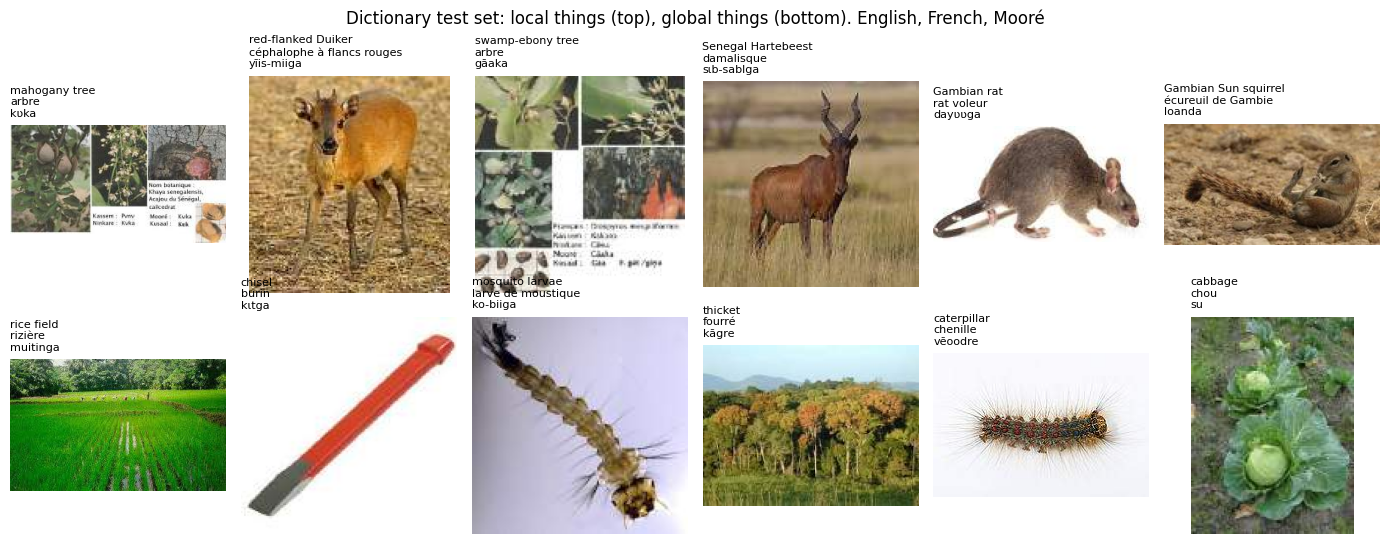

In [5]:
def show_photos(items, title):
    fig, axes = plt.subplots(2, 6, figsize=(14, 5.5))
    for ax, (_, item) in zip(axes.ravel(), items.iterrows()):
        ax.imshow(item["photo"])
        ax.set_title(
            f"{item['english'][:26]}\n{item['french'][:26]}\n{item['moore']}", fontsize=8, loc="left"
        )
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def six_photos(items, group):
    with_moore = items[(items["group"] == group) & (items["moore"] != "")]
    return with_moore.sample(6, random_state=seed)


show_photos(
    pd.concat([six_photos(dictionary_test, "local"), six_photos(dictionary_test, "global")]),
    "Dictionary test set: local things (top), global things (bottom). English, French, Mooré",
)

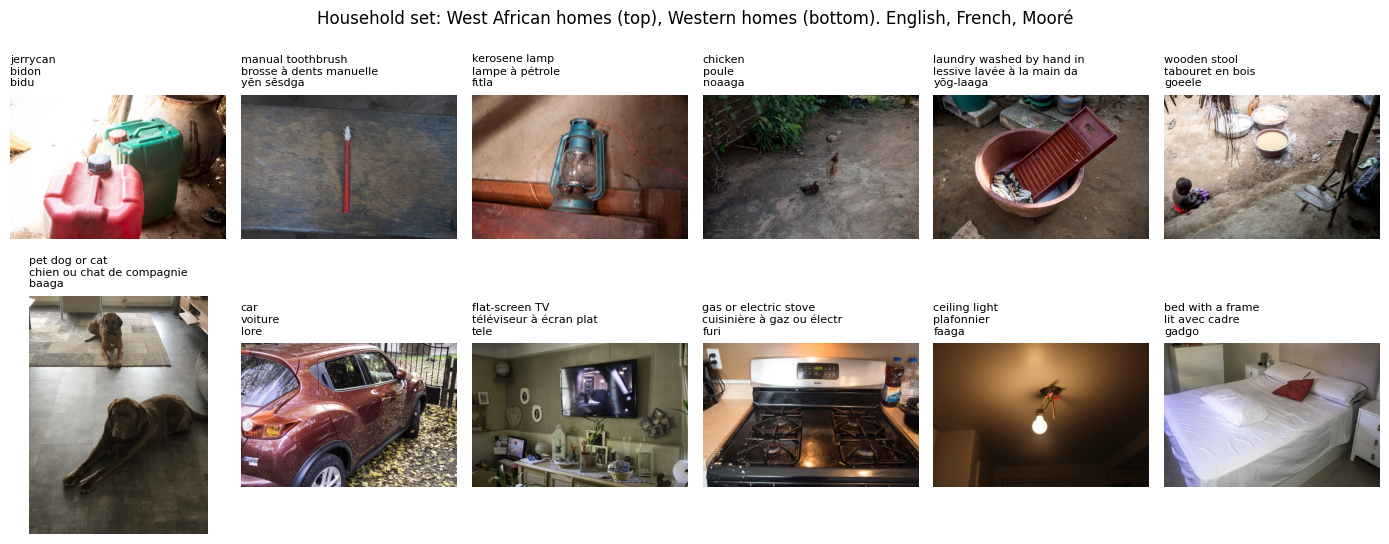

In [6]:
show_photos(
    pd.concat([six_photos(household, "west_african"), six_photos(household, "western")]),
    "Household set: West African homes (top), Western homes (bottom). English, French, Mooré",
)

### 1.1 Questions
Every photo is asked in two ways, in each language. In multiple choice, the question and the four options are in the language being tested. In the dictionary set the wrong options come from the same category. In the household set they are the Western look-alike (or a West African variant, for a Western photo) and two names from other categories. Each question is asked twice with the options in a different order, so that a preference for a letter cancels out.

In naming, the question is "What is the main thing in this image?" in English and French. For Mooré the instruction is written in English and asks for the Mooré word, so it tests answering in Mooré and not understanding a Mooré question. The Mooré multiple-choice question ("Kãngã yaa bõe?", what is this?) is in Mooré.

Every multiple-choice prompt ends with the same line, `Answer with the letter only.`

The three languages are compared on the same photos: a photo is kept only if it has valid questions in English, French and Mooré.

In [7]:
choice_question = {
    "english": "What is the main thing shown in this image? Choose one answer.",
    "french": "Quel est l'élément principal montré sur cette image ? Choisissez une réponse.",
    "moore": "Kãngã yaa bõe?",
}
answer_format = "Answer with the letter only."
naming_prompt = {
    "english": "What is the main thing in this image? Answer with a short name only.",
    "french": "Quel est l'élément principal de cette image ? Répondez par un nom court seulement.",
    "moore": "Give the Moore (Mooré, Mossi) name of the main thing in this image. Answer with the Moore word only.",
}


def arranged_options(item_id, correct, wrong):
    """The four options in two orders. In the second order the wrong options are reversed and the right one moves two places."""
    shuffler = random.Random(f"{seed}-{item_id}")
    position = shuffler.randrange(len(option_letters))
    shuffled = shuffler.sample(wrong, len(wrong))
    first, second = shuffled.copy(), shuffled[::-1]
    first.insert(position, correct)
    second.insert((position + 2) % len(option_letters), correct)
    return [(first, position), (second, (position + 2) % len(option_letters))]


def multiple_choice_prompt(language, options):
    lines = [f"{letter}. {option}" for letter, option in zip(option_letters, options)]
    return "\n".join([choice_question[language]] + lines + [answer_format])


def normalize(text):
    text = unicodedata.normalize("NFD", str(text).lower())
    text = "".join(char for char in text if unicodedata.category(char) != "Mn")
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s'-]", " ", text)).strip()


def build_questions(items):
    rows = []
    for _, item in items.iterrows():
        for language in languages:
            correct, wrong = item[language], item["wrong_" + language]
            if not correct:
                continue
            rows.append(
                {
                    "id": item["id"],
                    "language": language,
                    "task": "naming",
                    "order": 0,
                    "prompt": naming_prompt[language],
                    "expected": "",
                }
            )
            if (
                len(wrong) == 3
                and all(wrong)
                and len({normalize(option) for option in [correct] + wrong}) == 4
            ):
                for order, (options, position) in enumerate(arranged_options(item["id"], correct, wrong)):
                    rows.append(
                        {
                            "id": item["id"],
                            "language": language,
                            "task": "multiple choice",
                            "order": order,
                            "prompt": multiple_choice_prompt(language, options),
                            "expected": option_letters[position],
                        }
                    )
    asked = pd.DataFrame(rows)
    in_every_language = asked.groupby(["id", "task"])["language"].transform("nunique") == len(languages)
    return asked[in_every_language].reset_index(drop=True)


questions = {name: build_questions(items) for name, items in test_sets.items()}
print("Example of a household multiple-choice prompt:")
print(questions["household"].query("task == 'multiple choice'").iloc[0]["prompt"])
for name in ("dictionary", "household"):
    print(name, "photos with questions:", questions[name].groupby("task")["id"].nunique().to_dict())

Example of a household multiple-choice prompt:
What is the main thing shown in this image? Choose one answer.
A. clay pot
B. stainless steel pot
C. plastic chair
D. gas or electric stove
Answer with the letter only.
dictionary photos with questions: {'multiple choice': 162, 'naming': 162}
household photos with questions: {'multiple choice': 112, 'naming': 181}


## 2. Evaluation
Each question is asked once and the model takes its most likely answer, so there is no randomness. For multiple choice I read the model's scores for the letters A, B, C and D as the first word of its reply and take the highest. For naming the model writes up to 16 tokens.

A naming answer in English or French is correct when it contains one of the accepted names: the words of the dictionary translation and the scientific name for the dictionary set, a short list of names of the object for the household set (a "pot" is correct for a clay pot and for a steel pot). This is strict: "lézard" for a photo whose French name is "margouillat" counts as wrong. A Mooré answer is correct when it equals the dictionary word or one of its spelling variants once accents are removed, and I also compute chrF++, which scores how many letters the answer shares with the right word. For household photos I also count when the answer names the Western look-alike (a three-stone fire called a stove).

In [8]:
def load_model(name, four_bit=False, adapter=None):
    processor = AutoProcessor.from_pretrained(name)
    processor.tokenizer.padding_side = "left"
    if hasattr(processor.image_processor, "do_image_splitting"):
        processor.image_processor.do_image_splitting = (
            False  # SmolVLM2 cuts photos into tiles, which only adds tokens for small photos
        )
    quantization = (
        BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.float16,
        )
        if four_bit
        else None
    )
    model = AutoModelForImageTextToText.from_pretrained(
        name, dtype=torch.float16, quantization_config=quantization, device_map={"": 0}
    )
    if adapter:
        model = PeftModel.from_pretrained(model, adapter)
    return model.eval(), processor


def free_memory():
    gc.collect()
    torch.cuda.empty_cache()


def model_inputs(model, processor, photos, prompts):
    chats = [
        [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
        for prompt in prompts
    ]
    texts = [
        processor.apply_chat_template(chat, add_generation_prompt=True, tokenize=False) for chat in chats
    ]
    inputs = processor(
        text=texts, images=[[photo] for photo in photos], padding=True, return_tensors="pt"
    ).to(model.device)
    return {key: value.half() if value.is_floating_point() else value for key, value in inputs.items()}


@torch.no_grad()
def choose_letters(model, processor, photos, prompts, batch_size=8):
    encode = processor.tokenizer.encode
    letter_ids = [
        [encode(letter, add_special_tokens=False)[-1], encode(" " + letter, add_special_tokens=False)[-1]]
        for letter in option_letters
    ]
    letters = []
    for start in range(0, len(prompts), batch_size):
        inputs = model_inputs(
            model, processor, photos[start : start + batch_size], prompts[start : start + batch_size]
        )
        scores = model(**inputs).logits[:, -1, :].float()
        best = torch.stack([scores[:, ids].max(dim=1).values for ids in letter_ids], dim=1).argmax(dim=1)
        letters += [option_letters[i] for i in best.tolist()]
    return letters


@torch.no_grad()
def write_names(model, processor, photos, prompts, batch_size=8):
    names = []
    for start in range(0, len(prompts), batch_size):
        inputs = model_inputs(
            model, processor, photos[start : start + batch_size], prompts[start : start + batch_size]
        )
        generated = model.generate(**inputs, max_new_tokens=16, do_sample=False)
        names += [
            name.strip()
            for name in processor.batch_decode(
                generated[:, inputs["input_ids"].shape[1] :], skip_special_tokens=True
            )
        ]
    return names

In [9]:
def contains(text, name):
    """The name as a whole word, singular or plural (pot, pots, maison, maisons)."""
    return bool(name) and re.search(r"(?<!\w)" + re.escape(name) + r"(?:e?s|x)?(?!\w)", text) is not None


def judge_name(item, language, response):
    answer = normalize(response.split("\n")[0])
    if language == "moore":
        return "correct" if answer in {normalize(word) for word in item["accepted_moore"]} else "wrong"
    if any(contains(answer, normalize(name)) for name in item["accepted_" + language]):
        return "correct"
    if any(contains(answer, normalize(name)) for name in item["lookalike"]):
        return "western look-alike"
    return "wrong"


def chrf_score(item, response):
    answer = normalize(response.split("\n")[0])
    return sacrebleu.sentence_chrf(
        answer, [normalize(word) for word in item["accepted_moore"]], word_order=2
    ).score


def judge(answered, items):
    by_id = items.set_index("id").to_dict("index")
    outcomes, chrf = [], []
    for row in answered.itertuples():
        item = by_id[row.id]
        if row.task == "multiple choice":
            outcomes.append("correct" if row.response == row.expected else "wrong")
        else:
            outcomes.append(judge_name(item, row.language, row.response))
        chrf.append(
            chrf_score(item, row.response) if row.task == "naming" and row.language == "moore" else None
        )
    return answered.assign(
        outcome=outcomes, correct=[int(outcome == "correct") for outcome in outcomes], chrf=chrf
    )


def answer_questions(model, processor, asked, items):
    photos = dict(zip(items["id"], items["photo"]))
    responses = pd.Series("", index=asked.index)
    for task, ask in (("multiple choice", choose_letters), ("naming", write_names)):
        part = asked[asked["task"] == task]
        responses[part.index] = ask(model, processor, [photos[i] for i in part["id"]], list(part["prompt"]))
    return asked.assign(response=responses)

### 2.1 The main model, in fp16
Qwen3-VL-4B-Instruct on all dictionary test photos and household photos, and on the household photos shrunk to 113 pixels wide, about the size of the smallest dictionary photos. The shrunk set tests whether resolution alone explains a gap between West African and Western photos.

In [10]:
answer_tables = []
main_label = "Qwen3-VL-4B"


def evaluate(label, model_name, test_names, four_bit=False, adapter=None, subset=None):
    model, processor = load_model(model_name, four_bit, adapter)
    for name in test_names:
        asked = (
            questions[name] if subset is None else questions[name][questions[name]["id"].isin(subset[name])]
        )
        answered = judge(answer_questions(model, processor, asked, test_sets[name]), test_sets[name])
        answer_tables.append(
            answered.assign(model=label, test=name, group=answered["id"].map(group_of[name]))
        )
    del model, processor
    free_memory()


evaluate(main_label, qwen_4b, ["dictionary", "household", "household_113px"])

### 2.2 Two smaller models
The same questions on a fixed random sample of 150 photos per test set: Qwen3-VL-2B and SmolVLM2-2.2B.

In [11]:
subset = {
    name: set(questions[name]["id"].drop_duplicates().sample(sample_size, random_state=seed))
    for name in ("dictionary", "household")
}
other_labels = ["Qwen3-VL-2B", "SmolVLM2-2.2B"]
evaluate(other_labels[0], qwen_2b, ["dictionary", "household"], subset=subset)
evaluate(other_labels[1], smolvlm_2b, ["dictionary", "household"], subset=subset)

### 2.3 A check on the prompt
My first French prompt had no instruction about how to answer, and French scored much lower than English. This cell asks the same 100 French dictionary questions with no final line, with the English line and with a French line. The rest of the notebook uses the English line for every language.

In [12]:
model, processor = load_model(qwen_4b)
french_questions = (
    questions["dictionary"].query("language == 'french' and task == 'multiple choice'").head(100)
)
dictionary_photos = dict(zip(dictionary_test["id"], dictionary_test["photo"]))
for name, ending in (
    ("no instruction", ""),
    ("English instruction", answer_format),
    ("French instruction", "Répondez avec la lettre seulement."),
):
    prompts = [prompt.replace(answer_format, ending).strip() for prompt in french_questions["prompt"]]
    letters = choose_letters(
        model, processor, [dictionary_photos[i] for i in french_questions["id"]], prompts
    )
    print(
        f"French multiple choice, {name}: {np.mean(np.array(letters) == french_questions['expected'].to_numpy()):.1%} correct"
    )
del model, processor
free_memory()

French multiple choice, no instruction: 76.0% correct
French multiple choice, English instruction: 96.0% correct
French multiple choice, French instruction: 95.0% correct


Without the instruction line French multiple choice gets 76% right. With the English line it gets 96% and with a French line 95%. What helps is having the line, in either language, so every prompt in this notebook ends with the English one.

## 3. Fine-tuning
Does a small amount of Mooré help? I train two LoRA adapters, small extra weights added on top of the model, on the same photos of the dictionary train split. The base model is loaded in 4-bit to save memory and only its text part is trained, not the part that reads images. Both adapters get 220 steps of 8 examples (1,760 examples) with the same learning-rate schedule.

The first adapter learns from English and French: for each photo, the name and a multiple-choice question in each language, and a one-sentence description in each language. The second adapter gets the same, but the two descriptions are replaced by the Mooré name and a Mooré multiple-choice question.

"Before" is the 4-bit model without adapter and "after" is each adapter. All are tested on the questions of section 2.

In [13]:
def naming_and_choice_examples(item, language_list):
    examples = []
    for language in language_list:
        correct, wrong = item[language], item["wrong_" + language]
        examples.append((item["photo"], naming_prompt[language], correct))
        if all(wrong):
            options, position = arranged_options(item["id"], correct, wrong)[0]
            examples.append(
                (item["photo"], multiple_choice_prompt(language, options), option_letters[position])
            )
    return examples


def description_examples(item):
    article = "an" if item["english"][0].lower() in "aeiou" else "a"
    return [
        (
            item["photo"],
            "Describe what you see in one short sentence.",
            f"This is {article} {item['english']}.",
        ),
        (item["photo"], "Décrivez ce que vous voyez en une courte phrase.", f"C'est : {item['french']}."),
    ]


english_french_examples = [
    example
    for _, item in train_items.iterrows()
    for example in naming_and_choice_examples(item, ["english", "french"]) + description_examples(item)
]
with_moore_examples = [
    example for _, item in train_items.iterrows() for example in naming_and_choice_examples(item, languages)
]
random.Random(seed).shuffle(english_french_examples)
random.Random(seed).shuffle(with_moore_examples)
print(len(english_french_examples), "examples without Mooré,", len(with_moore_examples), "with Mooré")

5508 examples without Mooré, 5508 with Mooré


In [14]:
def training_batch(model, processor, examples):
    photos = [[photo] for photo, _, _ in examples]
    chat = lambda prompt: [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    full_texts = [
        processor.apply_chat_template(
            chat(prompt) + [{"role": "assistant", "content": [{"type": "text", "text": answer}]}],
            tokenize=False,
        )
        for _, prompt, answer in examples
    ]
    prompt_texts = [
        processor.apply_chat_template(chat(prompt), add_generation_prompt=True, tokenize=False)
        for _, prompt, _ in examples
    ]
    inputs = processor(text=full_texts, images=photos, padding=True, return_tensors="pt").to(model.device)
    prompt_lengths = processor(text=prompt_texts, images=photos, padding=True, return_tensors="pt")[
        "attention_mask"
    ].sum(dim=1)
    labels = inputs["input_ids"].clone()
    labels[inputs["attention_mask"] == 0] = -100
    for row, length in enumerate(prompt_lengths):
        labels[row, :length] = -100  # the loss is only on the answer
    inputs = {key: value.half() if value.is_floating_point() else value for key, value in inputs.items()}
    return dict(inputs, labels=labels)


def add_lora(model):
    config = LoraConfig(
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        task_type="CAUSAL_LM",
        target_modules=r".*language_model.*\.(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)",
    )
    model = get_peft_model(model, config).train()
    parameters = [p for p in model.parameters() if p.requires_grad]
    for parameter in parameters:
        parameter.data = parameter.data.float()
    return model, parameters


def learning_rate_factor(step, steps, warmup_steps=10, final_fraction=0.1):
    warmup = min(1, (step + 1) / warmup_steps)
    cosine = 0.5 * (1 + np.cos(np.pi * step / steps))
    return warmup * (final_fraction + (1 - final_fraction) * cosine)


def train_adapter(examples, name, steps=220, batch_size=4, accumulation=2, learning_rate=2e-4):
    torch.manual_seed(seed)
    model, processor = load_model(qwen_4b, four_bit=True)
    processor.tokenizer.padding_side = "right"
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    model, parameters = add_lora(model)
    optimizer = torch.optim.AdamW(parameters, lr=learning_rate)
    scaler = torch.amp.GradScaler("cuda")
    losses, position = [], 0
    for step in range(steps):
        for group in optimizer.param_groups:
            group["lr"] = learning_rate * learning_rate_factor(step, steps)
        step_loss = 0
        for _ in range(accumulation):
            batch = training_batch(model, processor, examples[position : position + batch_size])
            position = (position + batch_size) % (len(examples) - batch_size)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**batch).loss / accumulation
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(parameters, 1.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        losses.append(step_loss)
        if (step + 1) % 20 == 0:
            print(f"{name}: step {step + 1}/{steps}, loss {np.mean(losses[-20:]):.3f}")
    model.save_pretrained(f"adapters/{name}")
    del model, processor, optimizer, scaler, parameters, batch, loss
    free_memory()
    return losses

### 3.1 Before
The 4-bit model without adapter.

In [15]:
before_label = "Qwen3-VL-4B 4-bit, before"
evaluate(before_label, qwen_4b, ["dictionary", "household"], four_bit=True)

### 3.2 Training

In [16]:
training_loss = {
    "english_french": train_adapter(english_french_examples, "english_french"),
    "english_french_moore": train_adapter(with_moore_examples, "english_french_moore"),
}

english_french: step 20/220, loss 1.914
english_french: step 40/220, loss 1.007
english_french: step 60/220, loss 1.027
english_french: step 80/220, loss 0.864
english_french: step 100/220, loss 0.878
english_french: step 120/220, loss 0.958
english_french: step 140/220, loss 0.792
english_french: step 160/220, loss 0.846
english_french: step 180/220, loss 0.772
english_french: step 200/220, loss 0.810
english_french: step 220/220, loss 0.729
english_french_moore: step 20/220, loss 2.061
english_french_moore: step 40/220, loss 1.722
english_french_moore: step 60/220, loss 1.624
english_french_moore: step 80/220, loss 1.649
english_french_moore: step 100/220, loss 1.721
english_french_moore: step 120/220, loss 1.532
english_french_moore: step 140/220, loss 1.588
english_french_moore: step 160/220, loss 1.482
english_french_moore: step 180/220, loss 1.496
english_french_moore: step 200/220, loss 1.446
english_french_moore: step 220/220, loss 1.381


### 3.3 After

In [17]:
adapter_labels = {
    "english_french": "after, English and French",
    "english_french_moore": "after, English, French and Mooré",
}
for name, label in adapter_labels.items():
    evaluate(label, qwen_4b, ["dictionary", "household"], four_bit=True, adapter=f"adapters/{name}")

## 4. Results
Accuracy in percent. The line on each bar is a 95% interval: the range of accuracies obtained when the test photos are redrawn at random 2000 times (a bootstrap). Chance is 25% for multiple choice. The two orders of a multiple-choice question count as one photo.

In [18]:
results = pd.concat(answer_tables, ignore_index=True)
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
results.drop(columns="prompt").to_csv("results/answers.csv", index=False)


def bootstrap_interval(values):
    means = rng.choice(values, (bootstrap_resamples, len(values))).mean(axis=1)
    return 100 * np.percentile(means, [2.5, 97.5])


def accuracy_table(answers, by):
    rows = []
    for key, part in answers.groupby(by):
        per_photo = part.groupby("id")["correct"].mean().to_numpy()
        low, high = bootstrap_interval(per_photo)
        rows.append(
            {
                **dict(zip(by, key)),
                "photos": len(per_photo),
                "accuracy": 100 * per_photo.mean(),
                "low": low,
                "high": high,
            }
        )
    return pd.DataFrame(rows).round(1)


accuracy = accuracy_table(results, ["model", "test", "task", "language", "group"])
accuracy.to_csv("results/accuracy.csv", index=False)


def plot_accuracy(table, series_column, series_values, title, filename):
    """One panel per task, bars per language, one colour per value of `series_column`."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    width = 0.8 / len(series_values)
    for ax, task in zip(axes, ("multiple choice", "naming")):
        for k, value in enumerate(series_values):
            part = (
                table[(table["task"] == task) & (table[series_column] == value)]
                .set_index("language")
                .reindex(languages)
            )
            ax.bar(
                np.arange(len(languages)) + (k - (len(series_values) - 1) / 2) * width,
                part["accuracy"],
                width,
                label=f"{str(value).replace('_', ' ')} ({int(part['photos'].max())} photos)",
                yerr=[part["accuracy"] - part["low"], part["high"] - part["accuracy"]],
                capsize=2,
            )
        ax.set_xticks(range(len(languages)), language_names)
        ax.set_title(task)
        ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    axes[0].axhline(25, color="grey", linestyle=":")
    axes[0].set_ylabel("correct answers (%)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"figures/{filename}.png", dpi=200, bbox_inches="tight")
    plt.show()

### 4.1 Main model: language and where the thing is from

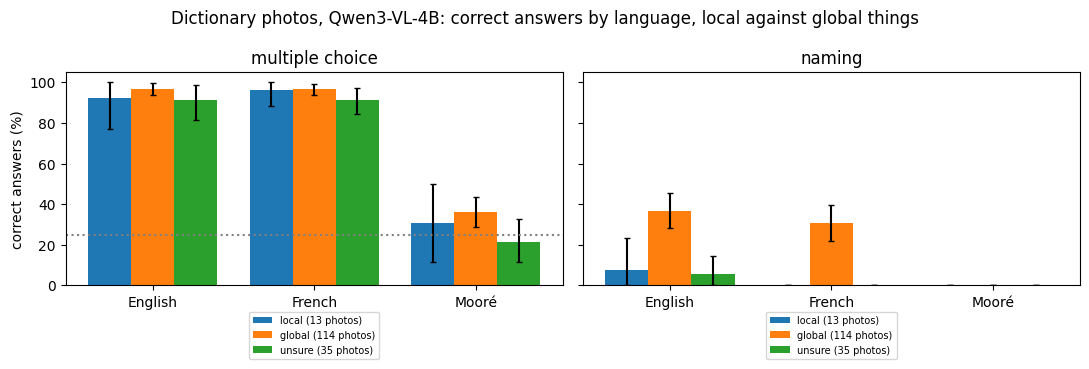

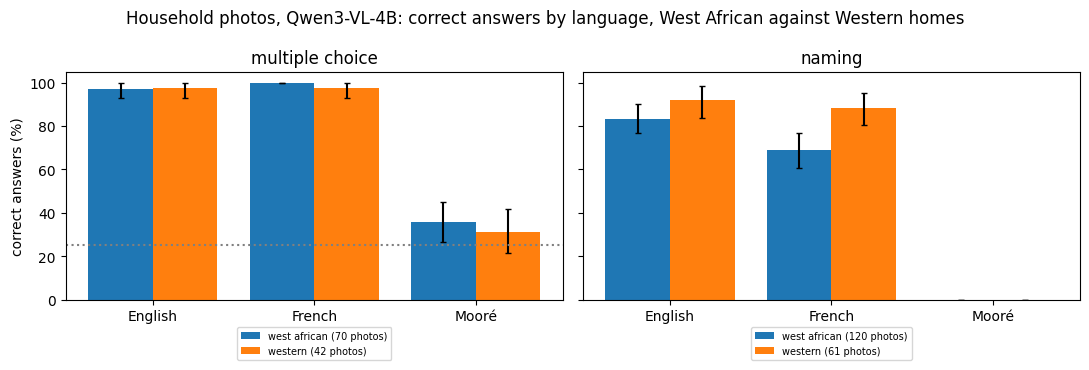

In [19]:
main = accuracy[accuracy["model"] == main_label]
plot_accuracy(
    main[main["test"] == "dictionary"],
    "group",
    ["local", "global", "unsure"],
    "Dictionary photos, Qwen3-VL-4B: correct answers by language, local against global things",
    "dictionary_by_language_and_locality",
)
plot_accuracy(
    main[main["test"] == "household"],
    "group",
    ["west_african", "western"],
    "Household photos, Qwen3-VL-4B: correct answers by language, West African against Western homes",
    "household_by_language_and_group",
)

Gap between the two groups in points, with a 95% bootstrap interval (local minus global for the dictionary photos, West African minus Western for the household photos). A negative gap means the model does worse on the local or West African photos.

In [20]:
def group_gaps(answers, test, first, second):
    rows = []
    for (model, task, language), part in answers[
        (answers["test"] == test) & answers["group"].isin([first, second])
    ].groupby(["model", "task", "language"]):
        first_photos = part[part["group"] == first].groupby("id")["correct"].mean().to_numpy()
        second_photos = part[part["group"] == second].groupby("id")["correct"].mean().to_numpy()
        gaps = rng.choice(first_photos, (bootstrap_resamples, len(first_photos))).mean(axis=1) - rng.choice(
            second_photos, (bootstrap_resamples, len(second_photos))
        ).mean(axis=1)
        low, high = 100 * np.percentile(gaps, [2.5, 97.5])
        rows.append(
            {
                "model": model,
                "test": test,
                "task": task,
                "language": language,
                "comparison": f"{first} minus {second}",
                "gap": 100 * (first_photos.mean() - second_photos.mean()),
                "low": low,
                "high": high,
            }
        )
    return pd.DataFrame(rows).round(1)


gaps = pd.concat(
    [
        group_gaps(results, "dictionary", "local", "global"),
        group_gaps(results, "household", "west_african", "western"),
        group_gaps(results, "household_113px", "west_african", "western"),
    ]
)
gaps.to_csv("results/gaps.csv", index=False)
gaps[(gaps["model"] == main_label) & (gaps["test"] != "household_113px")]

,model,test,task,language,comparison,gap,low,high
6,Qwen3-VL-4B,dictionary,multiple choice,english,local minus global,-4.6,-21.8,5.7
7,Qwen3-VL-4B,dictionary,multiple choice,french,local minus global,-0.8,-9.8,4.8
8,Qwen3-VL-4B,dictionary,multiple choice,moore,local minus global,-5.2,-25.3,16.2
9,Qwen3-VL-4B,dictionary,naming,english,local minus global,-29.1,-43.9,-10.5
10,Qwen3-VL-4B,dictionary,naming,french,local minus global,-30.7,-39.5,-21.9
11,Qwen3-VL-4B,dictionary,naming,moore,local minus global,0.0,0.0,0.0
6,Qwen3-VL-4B,household,multiple choice,english,west_african minus western,-0.5,-5.7,5.7
7,Qwen3-VL-4B,household,multiple choice,french,west_african minus western,2.4,0.0,7.1
8,Qwen3-VL-4B,household,multiple choice,moore,west_african minus western,4.8,-9.5,18.3
9,Qwen3-VL-4B,household,naming,english,west_african minus western,-8.5,-17.6,0.6


The 13 local dictionary photos, with the name the main model gives in English:

In [21]:
local_photos = results[
    (results["model"] == main_label)
    & (results["test"] == "dictionary")
    & (results["group"] == "local")
    & (results["task"] == "naming")
    & (results["language"] == "english")
]
english_names = dict(zip(dictionary_test["id"], dictionary_test["english"]))
local_photos.assign(photo=local_photos["id"].map(english_names))[["photo", "response", "outcome"]].reset_index(drop=True)

,photo,response,outcome
0,lizard,Lizard,correct
1,Gambian rat,rat,wrong
2,Senegal coucal,bird,wrong
3,swamp-ebony tree,Plant,wrong
4,dawadawa seeds cooked and washed,Lentils,wrong
5,mahogany tree,Kassem,wrong
6,Gambian Sun squirrel,Squirrel,wrong
7,groundnut sauce,soup,wrong
8,giant Gambian rat,rat,wrong
9,Senegal Hartebeest,Antelope,wrong


On multiple choice the model is right 91 to 97% of the time in English and French, for local, global and unsure photos alike. With four options from the same category it can find the answer by elimination, so this task cannot show the problem. Naming can. In English the model names 37% of the global photos and 8% of the local ones, a gap of 29 points (interval from -44 to -11). In French it is 31% and 0%.

The table shows what goes wrong on the 13 local photos. The model finds the family (rat, bird, antelope, deer, soup) but not the species or the dish, and sometimes it is far off: dawadawa seeds become lentils or clams, and the mahogany tree becomes "Kassem", a language name printed on its plate. With 13 photos the interval is wide, but it does not include zero.

What the model answers instead, in English and French, on West African household photos: share of naming answers in each outcome (%). "western look-alike" means it named the Western version of the object.

In [22]:
west_african_naming = results[
    (results["model"] == main_label)
    & (results["test"] == "household")
    & (results["task"] == "naming")
    & (results["group"] == "west_african")
    & (results["language"] != "moore")
]
pd.crosstab(west_african_naming["language"], west_african_naming["outcome"], normalize="index").mul(
    100
).round(1)

outcome,correct,western look-alike,wrong
language,,,
english,83.3,1.7,15.0
french,69.2,3.3,27.5


Household photos behave the same way. Multiple choice is at 97 to 100% for West African and Western photos. In naming, West African photos get 83% in English and 69% in French, Western photos 92% and 89%. The French gap of 19 points is solid (interval -31 to -7). The English gap of 8.5 points could be chance (interval -18 to 0.6). The model rarely names the Western look-alike instead, in less than 4% of the answers. It just fails to name the thing.

Exact match is a harsh score for Mooré, so here is chrF++ between the answer and the right word (0 to 100), averaged over the photos:

In [23]:
chrf = results[(results["task"] == "naming") & (results["language"] == "moore")]
chrf.groupby(["model", "test"])["chrf"].mean().round(1)

model                             test           
Qwen3-VL-2B                       dictionary         4.8
                                  household          5.1
Qwen3-VL-4B                       dictionary         4.8
                                  household          5.6
                                  household_113px    5.7
Qwen3-VL-4B 4-bit, before         dictionary         4.4
                                  household          6.5
SmolVLM2-2.2B                     dictionary         4.9
                                  household          6.7
after, English and French         dictionary         5.1
                                  household          5.5
after, English, French and Mooré  dictionary         6.3
                                  household          6.5
Name: chrf, dtype: float64

Mooré is at chance on multiple choice (between 21 and 36%, against 25% for guessing) and at 0% on naming for every model. chrF++ stays around 5 out of 100. The model has no Mooré words for these objects.

### 4.2 Resolution
The household photos at their normal size and shrunk to 113 pixels wide. If West African photos were only harder because they are blurrier, shrinking the Western photos would close the gap.

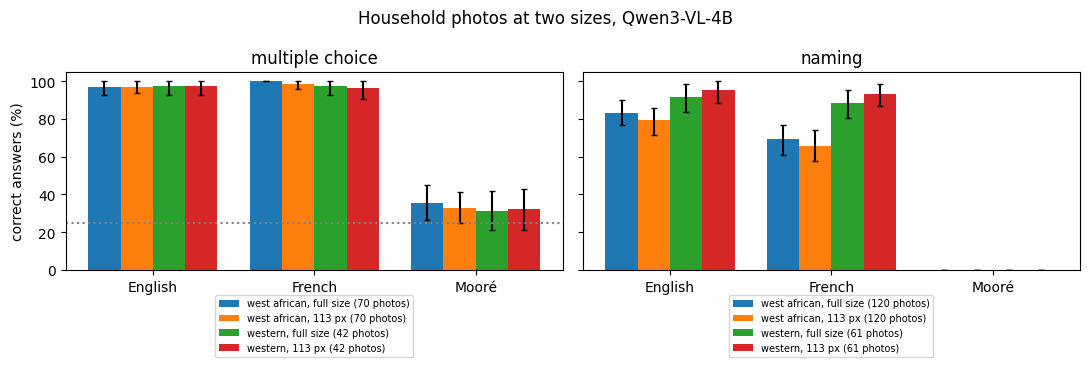

,model,test,task,language,comparison,gap,low,high
0,Qwen3-VL-4B,household_113px,multiple choice,english,west_african minus western,-0.5,-5.7,6.4
1,Qwen3-VL-4B,household_113px,multiple choice,french,west_african minus western,2.1,-2.9,9.3
3,Qwen3-VL-4B,household_113px,naming,english,west_african minus western,-15.9,-25.0,-6.8
4,Qwen3-VL-4B,household_113px,naming,french,west_african minus western,-27.6,-37.7,-16.8


In [24]:
resolution = main[main["test"].isin(["household", "household_113px"])].copy()
sizes = resolution["test"].map({"household": "full size", "household_113px": "113 px"})
resolution["series"] = resolution["group"].str.replace("_", " ") + ", " + sizes
plot_accuracy(
    resolution,
    "series",
    ["west african, full size", "west african, 113 px", "western, full size", "western, 113 px"],
    "Household photos at two sizes, Qwen3-VL-4B",
    "household_resolution",
)
gaps[(gaps["model"] == main_label) & (gaps["test"] == "household_113px") & (gaps["language"] != "moore")]

At 113 pixels the West African photos barely change (83 to 79% in English, 69 to 66% in French) and the Western photos even gain a little (92 to 95% and 89 to 93%). The gap grows, to 16 points in English and 28 in French. Blur does not explain it.

### 4.3 Three models
The same 150-photo samples for the three models.

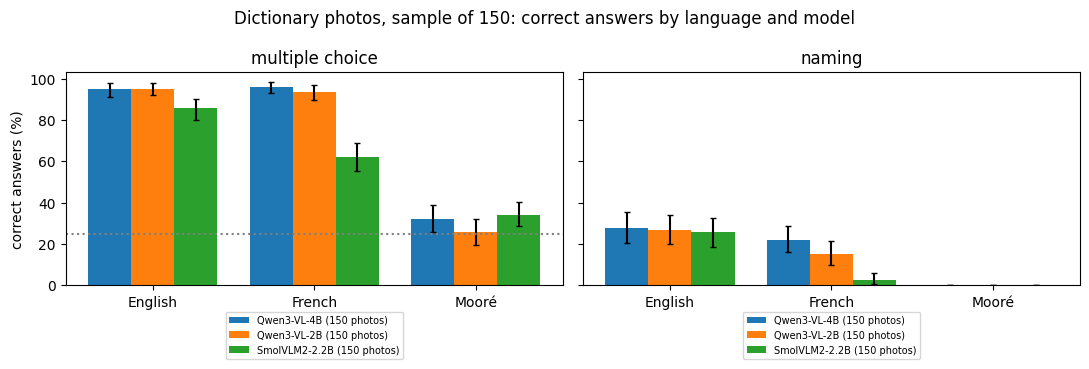

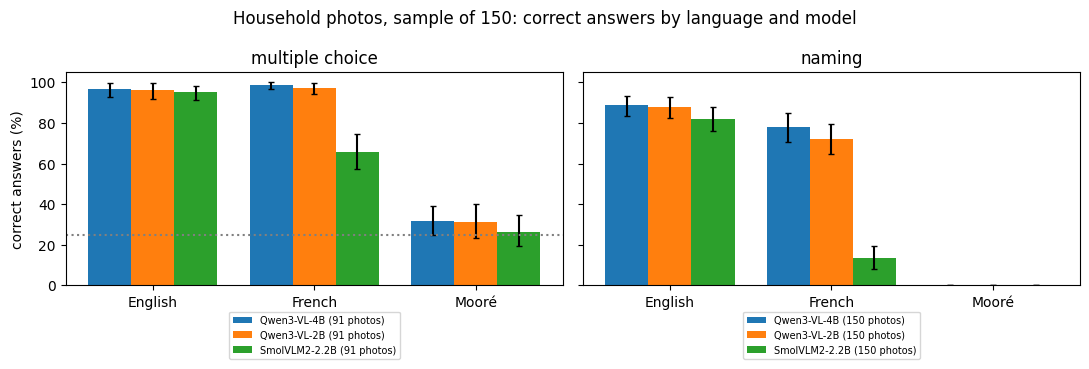

In [25]:
three_models = [main_label] + other_labels
for test in ("dictionary", "household"):
    sample = results[
        (results["test"] == test) & results["id"].isin(subset[test]) & results["model"].isin(three_models)
    ]
    table = accuracy_table(sample.assign(group="all"), ["model", "test", "task", "language", "group"])
    plot_accuracy(
        table,
        "model",
        three_models,
        f"{test.capitalize()} photos, sample of {sample_size}: correct answers by language and model",
        f"{test}_three_models",
    )

Qwen3-VL-2B is close to the 4B model almost everywhere. SmolVLM2 holds up in English (86% and 95% on multiple choice) but falls in French: 62% and 66% on multiple choice, 3% and 13% on naming. All three are at chance in Mooré.

### 4.4 Fine-tuning: before and after

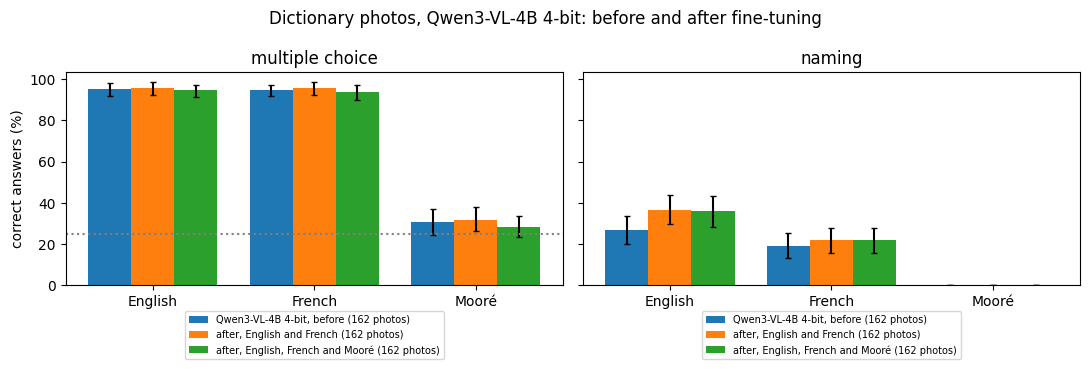

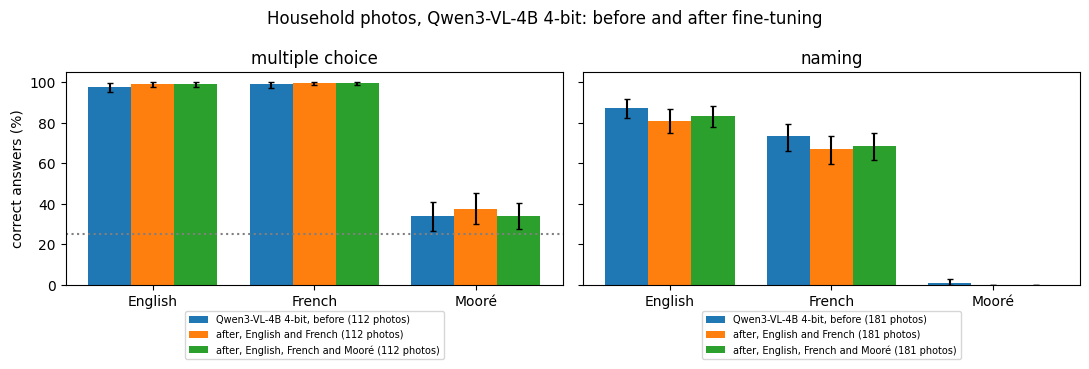

In [26]:
tuning_models = [before_label] + list(adapter_labels.values())
tuning_results = results[results["model"].isin(tuning_models)]
tuned = accuracy_table(tuning_results.assign(group="all"), ["model", "test", "task", "language", "group"])
tuned.to_csv("results/finetuning.csv", index=False)
for test in ("dictionary", "household"):
    plot_accuracy(
        tuned[tuned["test"] == test],
        "model",
        tuning_models,
        f"{test.capitalize()} photos, Qwen3-VL-4B 4-bit: before and after fine-tuning",
        f"{test}_finetuning",
    )

Photos whose multiple-choice score changed between before and after, with a sign test. "wrong to right" counts photos with a higher score after, "right to wrong" those with a lower score. Scores are percentages.

In [27]:
def photo_scores(answers):
    return answers[answers["task"] == "multiple choice"].groupby(["test", "language", "id"])["correct"].mean()


before = photo_scores(tuning_results[tuning_results["model"] == before_label])
rows = []
for label in adapter_labels.values():
    paired = pd.concat(
        {"before": before, "after": photo_scores(tuning_results[tuning_results["model"] == label])}, axis=1
    )
    for (test, language), part in paired.groupby(level=["test", "language"]):
        gained, lost = int((part["after"] > part["before"]).sum()), int(
            (part["after"] < part["before"]).sum()
        )
        rows.append(
            {
                "adapter": label,
                "test": test,
                "language": language,
                "before": 100 * part["before"].mean(),
                "after": 100 * part["after"].mean(),
                "wrong to right": gained,
                "right to wrong": lost,
                "p value": binomtest(gained, gained + lost).pvalue if gained + lost else 1.0,
            }
        )
changes = pd.DataFrame(rows).round(3)
changes.to_csv("results/finetuning_changes.csv", index=False)
changes

,adapter,test,language,before,after,wrong to right,right to wrong,p value
0,"after, English and French",dictionary,english,95.370,95.679,6,4,0.754
1,"after, English and French",dictionary,french,94.753,95.679,8,4,0.388
2,"after, English and French",dictionary,moore,30.556,31.790,31,25,0.504
3,"after, English and French",household,english,97.768,99.107,3,0,0.250
4,"after, English and French",household,french,99.107,99.554,1,0,1.000
5,"after, English and French",household,moore,33.929,37.500,23,14,0.188
6,"after, English, French and Mooré",dictionary,english,95.370,94.753,4,5,1.000
7,"after, English, French and Mooré",dictionary,french,94.753,93.827,4,5,1.000
8,"after, English, French and Mooré",dictionary,moore,30.556,28.395,34,34,1.000
9,"after, English, French and Mooré",household,english,97.768,99.107,3,0,0.250


Neither adapter teaches Mooré. Mooré multiple choice stays between 28 and 32% on dictionary photos and between 34 and 38% on household photos, naming stays at 0%, and no sign test finds a change (all p above 0.18). With the Mooré adapter chrF++ goes from 4.4 to 6.3 on dictionary photos, which is too small to matter.

English naming of dictionary photos goes from 27% to 36% with both adapters. I think they learn how the dictionary names things. It does not carry over: household naming gets a little worse (87% to 81% and 83% in English).

Training loss of the two adapters, averaged over 10 steps. It only shows that training worked. The comparison is in the tables above.

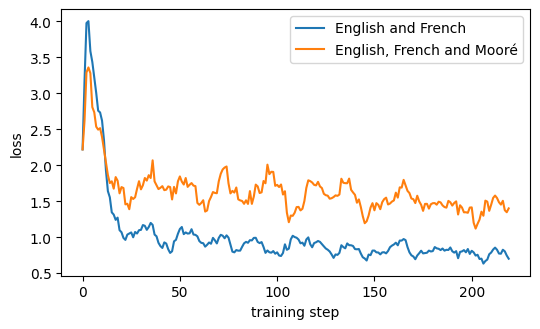

In [28]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for name, losses in training_loss.items():
    ax.plot(
        pd.Series(losses).rolling(10, min_periods=1).mean(), label=adapter_labels[name].replace("after, ", "")
    )
ax.set_xlabel("training step")
ax.set_ylabel("loss")
ax.legend()
plt.tight_layout()
plt.savefig("figures/training_loss.png", dpi=200)
plt.show()

The loss of the English and French adapter goes under 1. With Mooré it stays around 1.4 to 1.5. In 220 steps the model does not learn the Mooré answers.

### 4.5 Twelve mistakes
Twelve West African household photos that the main model named wrongly in English.

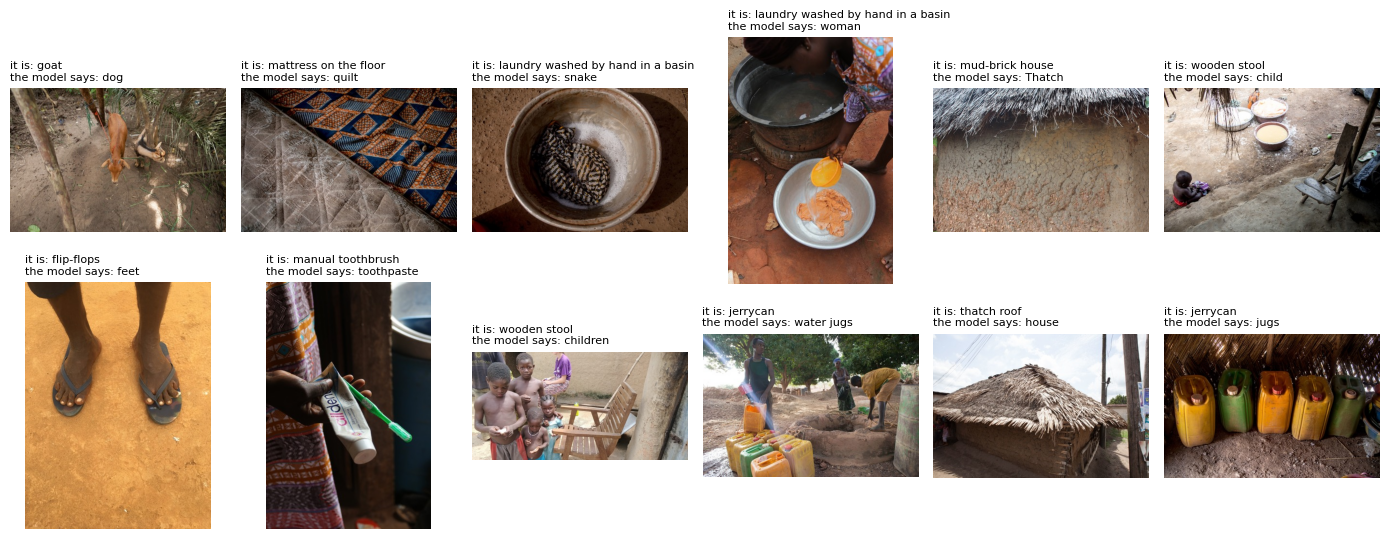

In [29]:
mistakes = results[
    (results["model"] == main_label)
    & (results["test"] == "household")
    & (results["language"] == "english")
    & (results["task"] == "naming")
    & (results["group"] == "west_african")
    & (results["correct"] == 0)
].sample(12, random_state=seed)
household_photos = dict(zip(household["id"], household["photo"]))
household_names = dict(zip(household["id"], household["english"]))
fig, axes = plt.subplots(2, 6, figsize=(14, 5.5))
for ax, (_, mistake) in zip(axes.ravel(), mistakes.iterrows()):
    ax.imshow(household_photos[mistake["id"]])
    ax.set_title(
        f"it is: {household_names[mistake['id']]}\nthe model says: {mistake['response'][:26]}",
        fontsize=8,
        loc="left",
    )
    ax.axis("off")
plt.tight_layout()
plt.savefig("figures/household_mistakes.png", dpi=200)
plt.show()

Some of these mistakes are real: a goat called a dog, a mattress called a quilt, laundry in a basin called a snake. Others come from the photo. The model names the feet for the flip-flops, the children for the stool and the toothpaste for the toothbrush. A household photo has people and several objects, so the main thing is not always the one I labelled. That lowers the naming scores in every language.

### 4.6 What I take from this
West African things are named worse than Western ones, but only in naming: by 8 points in English and 19 in French on household photos, and the local dictionary things are named at the family level only. Multiple choice hides it. English and French give similar results for the Qwen models, SmolVLM2 fails in French, and in Mooré every model is at chance. Fine-tuning with 1,760 examples does not change that.

## 5. Upload
The adapters, the answers, the tables and the figures go to the public Hugging Face bucket `anyantudre/moore-vision-blind-spot`, in the folders `model`, `results` and `figures`.

In [30]:
create_bucket(bucket, private=False, exist_ok=True, token=hf_token)
for folder, destination in (("adapters", "model"), ("results", "results"), ("figures", "figures")):
    sync_bucket(folder, f"hf://buckets/{bucket}/{destination}", token=hf_token)

Sync plan: adapters -> hf://buckets/anyantudre/moore-vision-blind-spot/model
  Uploads: 6
  Downloads: 0
  Deletes: 0
  Skips: 0
Syncing...
Sync completed.
Sync plan: results -> hf://buckets/anyantudre/moore-vision-blind-spot/results
  Uploads: 5
  Downloads: 0
  Deletes: 0
  Skips: 0
Syncing...
Sync completed.
Sync plan: figures -> hf://buckets/anyantudre/moore-vision-blind-spot/figures
  Uploads: 9
  Downloads: 0
  Deletes: 0
  Skips: 0
Syncing...
Sync completed.
